# IndicSynth — EDA (Hindi, Tamil, Telugu)
### Fake Indian-language speech for training the real-vs-AI voice detector

**Milestone 2 — Group Project**

IndicSynth (Sharma, Ekbote & Gupta, ACL 2025) is a synthetic speech dataset for 12 Indian
languages, loaded here from the Hugging Face Hub:
[`vdivyasharma/IndicSynth`](https://huggingface.co/datasets/vdivyasharma/IndicSynth).
Every clip was made from **Kathbath** recordings with one of two generators:

- **XTTS-v2**: text-to-speech that clones the voice of a Kathbath speaker from a reference recording;
- **FreeVC24**: voice conversion that turns a recording of one Kathbath speaker (source) into the
  voice of another (target).

In this project IndicSynth is the main source of **fake** speech for Hindi, Tamil and Telugu.

**Scope and operating constraints**

- **Three languages only.** The Hindi, Tamil and Telugu subsets hold about 658k clips (about 300 GB),
  so the audio is never downloaded in full.
- **Metadata of every clip.** Only the small text columns of the parquet files are read, so all
  tables in sections 1–3 cover the complete subsets.
- **Audio from a seeded sample.** 500 clips per generator and language (3,000 in total), spread over
  25 randomly chosen parquet row groups each, are decoded for the audio statistics.
- **No login needed.** The dataset is public; the notebook runs on Kaggle, Colab or a local machine
  (CPU only, internet required). A Hugging Face token is used if one is available, because anonymous
  downloads are rate-limited.
- **Reference:** Sharma, D. V., Ekbote, V., & Gupta, A. (2025). *IndicSynth: A Large-Scale Multilingual
  Synthetic Speech Dataset for Low-Resource Indian Languages*. ACL 2025
  ([aclanthology.org/2025.acl-long.1070](https://aclanthology.org/2025.acl-long.1070)).

**Contents**

0. Setup, configuration, seed 42
1. Data source and metadata checks (all clips)
2. Dataset overview — generators, speakers, gender, transcripts
3. Link to Kathbath — speakers, reference recordings and sentences
4. Audio statistics from a seeded sample — format, duration, level, silence, bandwidth
5. Split strategy and leakage
6. Conclusions and requirement checklist

## 0. Setup and configuration

The first cell only installs packages that are missing. The parquet files are read with
`pyarrow` through `HfFileSystem`, which downloads only the byte ranges that are needed: the text
columns for the metadata, and single row groups for the audio sample. Long steps print their
progress.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {
    "huggingface_hub": "huggingface_hub",
    "pyarrow": "pyarrow",
    "soundfile": "soundfile",
    "scipy": "scipy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "yaml": "pyyaml",
}
missing = [spec for module, spec in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are available.")

All required packages are available.


In [2]:
import hashlib
import io
import os
import tarfile
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import yaml
from huggingface_hub import HfFileSystem, get_token, hf_hub_download
from IPython.display import Markdown, display
from scipy.signal import welch

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

/home/himanshu/.cache/uv/archive-v0/jprMCEdSqExPZ-QN/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 42

HF_REPO_ID = "vdivyasharma/IndicSynth"
HF_REVISION = "c0a10386b723717aff682f757bd67f72983f269f"  # pinned for reproducibility
LANGUAGES = ["Hindi", "Tamil", "Telugu"]
GENERATORS = ["xtts_v2", "freevc24"]
GENERATOR_NAMES = {"xtts_v2": "XTTS-v2", "freevc24": "FreeVC24"}

GROUPS_PER_GENERATOR = 25  # parquet row groups sampled per language and generator
CLIPS_PER_GROUP = 20       # clips decoded from each sampled row group
N_THREADS = 6              # parallel downloads (more is faster but needs more memory)

KATHBATH_TRANSCRIPTS_URL = "https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/transcripts_n2w.tar"
KATHBATH_FOLDERS = {"Hindi": "hindi", "Tamil": "tamil", "Telugu": "telugu"}
KATHBATH_SPLITS = ["train", "valid", "test_known", "test"]  # "test" holds the unseen test speakers

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "working"
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Colours: one fixed hue per generator (checked for colour-blind separation).
COLORS = {"xtts_v2": "#2a78d6", "freevc24": "#eb6834"}
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10,
                     "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})

# A Hugging Face token is optional (the dataset is public) but gives much higher rate limits.
# It is taken from a Kaggle secret, the HF_TOKEN environment variable, or a saved `hf auth login`.
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

START_TIME = time.perf_counter()
fs = HfFileSystem(token=HF_TOKEN)
print("Hugging Face access:", "logged in" if (HF_TOKEN or get_token()) else "anonymous (may be rate-limited)")
print(f"Dataset: {HF_REPO_ID} @ {HF_REVISION[:8]} | languages: {', '.join(LANGUAGES)}")
print(f"Seed: {SEED} | audio sample: {GROUPS_PER_GENERATOR * CLIPS_PER_GROUP} clips per generator and language")
print(f"Working directory: {WORK_DIR}")

Hugging Face access: logged in
Dataset: vdivyasharma/IndicSynth @ c0a10386 | languages: Hindi, Tamil, Telugu
Seed: 42 | audio sample: 500 clips per generator and language
Working directory: /home/himanshu/myproject/dsai-project/temp/indicsynth/working


In [4]:
def show_table(frame, caption, precision=3):
    display(Markdown(f"**{caption}**"))
    display(frame.round(precision) if precision else frame)


def style_axes(ax, grid_axis="y"):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_MUTED)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def box_by_generator(frame, column, ylabel, title):
    """One panel per language, one box per generator."""
    fig, axes = plt.subplots(1, len(LANGUAGES), figsize=(11, 3.6), sharey=True)
    for ax, language in zip(axes, LANGUAGES):
        data = [frame[(frame.language == language) & (frame.generator == g)][column].dropna() for g in GENERATORS]
        parts = ax.boxplot(data, widths=0.5, patch_artist=True,
                           medianprops={"color": INK, "linewidth": 1.5},
                           whiskerprops={"color": INK_MUTED}, capprops={"color": INK_MUTED},
                           flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": INK_MUTED,
                                       "markeredgecolor": "none", "alpha": 0.4})
        for box, generator in zip(parts["boxes"], GENERATORS):
            box.set_facecolor(COLORS[generator])
            box.set_edgecolor(SURFACE)
        ax.set_xticks(range(1, len(GENERATORS) + 1), [GENERATOR_NAMES[g] for g in GENERATORS], color=INK)
        ax.set_title(language, color=INK)
        style_axes(ax)
    axes[0].set_ylabel(ylabel, color=INK)
    fig.suptitle(title, color=INK, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

## 1. Data source and metadata checks

Each language is a folder of parquet files with one row per clip:

| Column | Meaning |
|---|---|
| `audio` | WAV bytes and file name of the generated clip |
| `Generative Model` | `xtts_v2` or `freevc24` |
| `Target Speaker ID` | Kathbath speaker whose voice the clip imitates |
| `Source Speaker_ID` | FreeVC24 only: Kathbath speaker whose recording was converted |
| `Gender` | gender of the target speaker |
| `Target Reference Audio` | Kathbath recording used as the voice reference |
| `Source Reference Audio` | FreeVC24 only: Kathbath recording that was converted |
| `TTS Transcript` | XTTS-v2 only: the sentence that was synthesised |

All columns except the audio bytes are read for every file. The row group of each row is kept, so
that the audio sample in section 4 can download single row groups. Reading all 407 files takes
about an hour, so the result is saved to `indicsynth_metadata_raw.parquet` and reused when the
notebook is run again.

In [5]:
META_COLUMNS = ["audio.path", "Generative Model", "Source Speaker_ID", "Target Speaker ID", "Gender",
                "Source Reference Audio", "Target Reference Audio", "TTS Transcript"]
RENAME = {"Generative Model": "generator", "Source Speaker_ID": "source_speaker",
          "Target Speaker ID": "target_speaker", "Gender": "gender",
          "Source Reference Audio": "source_ref", "Target Reference Audio": "target_ref",
          "TTS Transcript": "transcript"}


def read_metadata(language, path):
    # cache_type="none" + pre_buffer: only the needed byte ranges are fetched, merged into one request per row group
    with fs.open(path, cache_type="none") as f:
        parquet = pq.ParquetFile(f, pre_buffer=True)
        table = parquet.read(columns=META_COLUMNS).to_pandas()
        group_sizes = [parquet.metadata.row_group(i).num_rows for i in range(parquet.metadata.num_row_groups)]
    table["audio_path"] = table.pop("audio").map(lambda audio: audio["path"])
    table = table.rename(columns=RENAME)
    table["language"] = language
    table["file"] = path.split("/")[-1]
    table["row_group"] = np.repeat(np.arange(len(group_sizes)), group_sizes)
    table["row_in_group"] = np.concatenate([np.arange(n) for n in group_sizes])
    return table


RAW_METADATA = WORK_DIR / "indicsynth_metadata_raw.parquet"

if RAW_METADATA.exists():
    meta = pd.read_parquet(RAW_METADATA)
    print(f"Loaded saved metadata of {len(meta):,} clips from {RAW_METADATA}")
else:
    jobs = []
    for language in LANGUAGES:
        files = sorted(fs.glob(f"datasets/{HF_REPO_ID}@{HF_REVISION}/{language}/*.parquet"))
        print(f"{language}: {len(files)} parquet files")
        jobs += [(language, path) for path in files]

    start = time.perf_counter()
    parts = []
    with ThreadPoolExecutor(N_THREADS) as pool:
        for i, part in enumerate(pool.map(lambda job: read_metadata(*job), jobs), start=1):
            parts.append(part)
            if i % 50 == 0 or i == len(jobs):
                print(f"  {i}/{len(jobs)} files read ({time.perf_counter() - start:.0f} s)", flush=True)
    meta = pd.concat(parts, ignore_index=True)
    meta["source_speaker"] = meta["source_speaker"].astype("Int64")
    meta["transcript"] = meta["transcript"].str.strip()
    meta.to_parquet(RAW_METADATA, index=False)
    print(f"Read metadata of {len(meta):,} clips in {time.perf_counter() - start:.0f} s")
meta.head()

Loaded saved metadata of 658,146 clips from /home/himanshu/myproject/dsai-project/temp/indicsynth/working/indicsynth_metadata_raw.parquet


,generator,source_speaker,target_speaker,gender,source_ref,target_ref,transcript,audio_path,language,file,row_group,row_in_group
0,freevc24,1087,1102,Female,844424930794018-1087-f.wav,844424930951247-1102-f.wav,NaN,freevc24____f____src_1087____tgt_1102___0.wav,Hindi,train-00000-of-00107.parquet,0,0
1,freevc24,1087,1102,Female,844424930794018-1087-f.wav,844424932473999-1102-f.wav,NaN,freevc24____f____src_1087____tgt_1102___1.wav,Hindi,train-00000-of-00107.parquet,0,1
2,freevc24,1087,1102,Female,844424930794018-1087-f.wav,844424932815989-1102-f.wav,NaN,freevc24____f____src_1087____tgt_1102___10.wav,Hindi,train-00000-of-00107.parquet,0,2
3,freevc24,1087,1102,Female,844424930794018-1087-f.wav,844424932911600-1102-f.wav,NaN,freevc24____f____src_1087____tgt_1102___11.wav,Hindi,train-00000-of-00107.parquet,0,3
4,freevc24,1087,1102,Female,844424930794018-1087-f.wav,844424932901830-1102-f.wav,NaN,freevc24____f____src_1087____tgt_1102___12.wav,Hindi,train-00000-of-00107.parquet,0,4


The checks below compare the metadata with the dataset card and with itself. Missing values are
judged per generator, because XTTS-v2 clips have no source speaker and FreeVC24 clips have no
transcript by design.

In [6]:
readme = hf_hub_download(HF_REPO_ID, "README.md", repo_type="dataset", revision=HF_REVISION)
card = yaml.safe_load(open(readme, encoding="utf-8").read().split("---")[1])
card_rows = {item["config_name"]: item["splits"][0]["num_examples"] for item in card["dataset_info"]}


def ref_parts(name):
    """'844424930794018-1087-f.wav' -> ('844424930794018-1087-f', 1087, 'f')."""
    stem = name[:-4] if isinstance(name, str) and name.endswith(".wav") else None
    if stem is None:
        return None, None, None
    _, speaker, gender = stem.split("-")
    return stem, int(speaker), gender


for side in ["target", "source"]:
    parts = meta[f"{side}_ref"].map(ref_parts)
    meta[f"{side}_ref_stem"] = parts.map(lambda p: p[0])
    meta[f"{side}_ref_speaker"] = parts.map(lambda p: p[1]).astype("Int64")
    meta[f"{side}_ref_gender"] = parts.map(lambda p: p[2])

xtts = meta[meta.generator == "xtts_v2"]
freevc = meta[meta.generator == "freevc24"]
checks = []


def add_check(name, observed, passed, info=False):
    status = "INFO" if info else ("PASS" if passed else "FAIL")
    checks.append({"check": name, "observed": observed, "status": status})


for language in LANGUAGES:
    rows = int((meta.language == language).sum())
    add_check(f"{language}: rows vs dataset card", f"{rows:,} / {card_rows[language]:,}", rows == card_rows[language])
add_check("Generator values", ", ".join(sorted(meta.generator.unique())), set(meta.generator) == set(GENERATORS))
add_check("Gender values", ", ".join(sorted(meta.gender.unique())), set(meta.gender) <= {"Female", "Male"})
add_check("Missing target speaker / gender / target reference",
          int(meta[["target_speaker", "gender", "target_ref"]].isna().sum().sum()),
          meta[["target_speaker", "gender", "target_ref"]].notna().all().all())
add_check("XTTS-v2: missing transcripts", int(xtts.transcript.isna().sum() + (xtts.transcript == "").sum()),
          xtts.transcript.notna().all() and (xtts.transcript != "").all())
add_check("XTTS-v2: source fields empty (as designed)", int(xtts[["source_speaker", "source_ref"]].notna().sum().sum()),
          xtts[["source_speaker", "source_ref"]].isna().all().all())
add_check("FreeVC24: missing source speaker / reference", int(freevc[["source_speaker", "source_ref"]].isna().sum().sum()),
          freevc[["source_speaker", "source_ref"]].notna().all().all())
add_check("FreeVC24: transcript empty (as designed)", int(freevc.transcript.notna().sum()), freevc.transcript.isna().all())
add_check("Target speaker ID matches target reference file name",
          int((meta.target_speaker != meta.target_ref_speaker).sum()), (meta.target_speaker == meta.target_ref_speaker).all())
add_check("Gender matches target reference file name",
          int((meta.gender.str[0].str.lower() != meta.target_ref_gender).sum()),
          (meta.gender.str[0].str.lower() == meta.target_ref_gender).all())
add_check("FreeVC24: source speaker ID matches source reference file name",
          int((freevc.source_speaker != freevc.source_ref_speaker).sum()),
          (freevc.source_speaker == freevc.source_ref_speaker).all())
add_check("Clip file name starts with its generator",
          int((~meta.apply(lambda r: r.audio_path.startswith(r.generator), axis=1)).sum()),
          meta.apply(lambda r: r.audio_path.startswith(r.generator), axis=1).all())
add_check("Duplicate clip file names (within a language)",
          int(meta.duplicated(["language", "audio_path"]).sum()), not meta.duplicated(["language", "audio_path"]).any())
add_check("XTTS-v2: sentence synthesised again from the same reference (separate clip)",
          int(xtts.duplicated(["language", "target_ref", "transcript"]).sum()), True, info=True)
add_check("FreeVC24: same source recording + same target reference twice",
          int(freevc.duplicated(["language", "source_ref", "target_ref"]).sum()),
          not freevc.duplicated(["language", "source_ref", "target_ref"]).any())

check_table = pd.DataFrame(checks)
show_table(check_table, "Table 1.1 — Metadata checks (all clips)", precision=0)

**Table 1.1 — Metadata checks (all clips)**

,check,observed,status
0,Hindi: rows vs dataset card,"205,938 / 205,938",PASS
1,Tamil: rows vs dataset card,"282,312 / 282,312",PASS
2,Telugu: rows vs dataset card,"169,896 / 169,896",PASS
3,Generator values,"freevc24, xtts_v2",PASS
4,Gender values,"Female, Male",PASS
5,Missing target speaker / gender / target refer...,0,PASS
6,XTTS-v2: missing transcripts,0,PASS
7,XTTS-v2: source fields empty (as designed),0,PASS
8,FreeVC24: missing source speaker / reference,0,PASS
9,FreeVC24: transcript empty (as designed),0,PASS


**Takeaway.** The metadata is complete and consistent. Row counts match the dataset card exactly
(205,938 Hindi, 282,312 Tamil, 169,896 Telugu; **658,146 clips** in total). Every clip has a target
speaker, gender and reference recording; speaker IDs and gender agree with the reference file names;
the empty fields follow the design (no source speaker for XTTS-v2, no transcript for FreeVC24); and
no clip file name repeats. 76 XTTS-v2 clips synthesise a sentence again from the same reference
recording. They are separate generated files, so they are kept; exact copies are removed later by
audio hash during preprocessing.

## 2. Dataset overview

All tables and figures in this section use the metadata of every clip.

In [7]:
overview = []
for language in LANGUAGES:
    for generator in GENERATORS:
        part = meta[(meta.language == language) & (meta.generator == generator)]
        overview.append({
            "language": language, "generator": GENERATOR_NAMES[generator], "clips": len(part),
            "target_speakers": part.target_speaker.nunique(),
            "source_speakers": part.source_speaker.nunique() if generator == "freevc24" else 0,
            "female_clips_pct": round(100 * (part.gender == "Female").mean(), 1),
            "reference_recordings": part.target_ref.nunique(),
            "clips_per_speaker_min": int(part.groupby("target_speaker").size().min()),
            "clips_per_speaker_max": int(part.groupby("target_speaker").size().max()),
        })
overview = pd.DataFrame(overview)
show_table(overview, "Table 2.1 — Clips, speakers and gender per language and generator", precision=1)

speakers = (meta.groupby(["language", "target_speaker"]).gender.first().reset_index()
            .groupby(["language", "gender"]).size().unstack(fill_value=0))
show_table(speakers, "Table 2.2 — Target speakers per language and gender", precision=0)

**Table 2.1 — Clips, speakers and gender per language and generator**

,language,generator,clips,target_speakers,source_speakers,female_clips_pct,reference_recordings,clips_per_speaker_min,clips_per_speaker_max
0,Hindi,XTTS-v2,101202,101,0,52.500,47258,1002,1002
1,Hindi,FreeVC24,104736,101,101,52.600,48361,1026,1040
2,Tamil,XTTS-v2,138276,138,0,23.200,48714,1002,1002
3,Tamil,FreeVC24,144036,138,138,22.700,49641,1023,1050
4,Telugu,XTTS-v2,84168,84,0,48.800,37315,1002,1002
5,Telugu,FreeVC24,85728,84,84,49.700,38212,912,1040


**Table 2.2 — Target speakers per language and gender**

gender,Female,Male
language,,
Hindi,53,48
Tamil,32,106
Telugu,41,43


**XTTS-v2 sentences and FreeVC24 speaker pairs.** XTTS-v2 synthesises a sentence in the voice of a
reference recording. FreeVC24 converts a whole recording, so the spoken content of a FreeVC24 clip
is the content of its source recording.

**Table 2.3 — XTTS-v2 transcripts**

,clips,distinct_sentences,words_min,words_median,words_max,clips_per_sentence
language,,,,,,
Hindi,101202,57881,5,12.000,31,1.750
Tamil,138276,61592,2,10.000,17,2.250
Telugu,84168,47262,4,10.000,19,1.780


**Table 2.4 — FreeVC24 source/target pairs**

,clips,speaker_pairs,same_speaker_pairs,cross_gender_clips_pct,source_recordings,clips_per_source_recording
language,,,,,,
Hindi,"104,736.000","5,012.000",0.000,0.000,"5,078.000",20.600
Tamil,"144,036.000","12,122.000",0.000,0.000,"9,187.000",15.700
Telugu,"85,728.000","3,446.000",0.000,0.000,"4,573.000",18.700


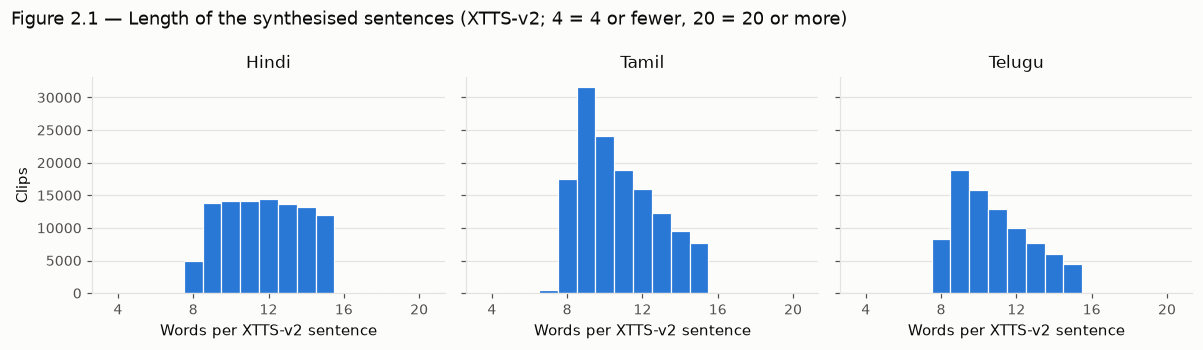

In [8]:
xtts = meta[meta.generator == "xtts_v2"].copy()
xtts["words"] = xtts.transcript.str.split().str.len()
text_stats = xtts.groupby("language").agg(
    clips=("transcript", "size"), distinct_sentences=("transcript", "nunique"),
    words_min=("words", "min"), words_median=("words", "median"), words_max=("words", "max"))
text_stats["clips_per_sentence"] = text_stats.clips / text_stats.distinct_sentences
show_table(text_stats, "Table 2.3 — XTTS-v2 transcripts", precision=2)

freevc = meta[meta.generator == "freevc24"]
pairs = freevc.groupby("language").apply(lambda part: pd.Series({
    "clips": len(part),
    "speaker_pairs": part[["source_speaker", "target_speaker"]].drop_duplicates().shape[0],
    "same_speaker_pairs": int((part.source_speaker == part.target_speaker).sum()),
    "cross_gender_clips_pct": round(100 * (part.source_ref_gender != part.target_ref_gender).mean(), 1),
    "source_recordings": part.source_ref.nunique(),
    "clips_per_source_recording": round(len(part) / part.source_ref.nunique(), 1),
}))
show_table(pairs, "Table 2.4 — FreeVC24 source/target pairs", precision=1)

fig, axes = plt.subplots(1, len(LANGUAGES), figsize=(11, 3.2), sharey=True)
for ax, language in zip(axes, LANGUAGES):
    words = xtts[xtts.language == language].words.clip(4, 20)  # the few shorter/longer sentences are counted at 4 / 20
    ax.hist(words, bins=np.arange(3.5, 21.5), color=COLORS["xtts_v2"], edgecolor=SURFACE, linewidth=0.8)
    ax.set_xticks(range(4, 21, 4))
    ax.set_title(language, color=INK)
    ax.set_xlabel("Words per XTTS-v2 sentence", color=INK)
    style_axes(ax)
axes[0].set_ylabel("Clips", color=INK)
fig.suptitle("Figure 2.1 — Length of the synthesised sentences (XTTS-v2; 4 = 4 or fewer, 20 = 20 or more)", color=INK, x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Takeaway.** Both generators are about equally represented in every language (Table 2.1), and
every target speaker has roughly 1,000 clips per generator, so no speaker dominates. Gender follows
the Kathbath speakers that were used: balanced for Hindi (53 female / 48 male speakers) and Telugu
(41 / 43), but **Tamil is mostly male** (32 / 106 speakers, 23% female clips), so samples drawn for
training need to be balanced by gender. Most XTTS-v2 sentences have 8–15 words, and each sentence
is used about twice. FreeVC24 always converts between two *different* speakers of the *same* gender,
and each source recording is converted into 16–21 target voices, so the spoken content of FreeVC24
clips repeats heavily.

## 3. Link to Kathbath — speakers, reference recordings and sentences

IndicSynth was built from Kathbath, which is also our source of **real** speech. Kathbath has its
own splits: `train`, `valid` and `test_known` share the same speakers, while `test` holds separate
speakers that never appear in training. The Kathbath transcript archive (209 MB, every file name
and sentence of every split) is downloaded to find out, for every IndicSynth clip:

- which Kathbath split its **speakers** belong to;
- which Kathbath split its **reference recording(s)** come from;
- for XTTS-v2, which Kathbath split its **sentence** comes from.

This decides how IndicSynth can be split without leaking speakers or sentences between train and
test. Our own generated set takes its sentences from Kathbath's `test` split, so any IndicSynth
sentence from that split is also checked.

In [9]:
KATHBATH_DIR = WORK_DIR / "kathbath"
KATHBATH_DIR.mkdir(exist_ok=True)
tar_path = KATHBATH_DIR / "transcripts_n2w.tar"
if not tar_path.exists():
    print("Downloading Kathbath transcripts ...")
    urllib.request.urlretrieve(KATHBATH_TRANSCRIPTS_URL, tar_path)

kathbath_rows = []
with tarfile.open(tar_path) as tar:
    for member in tar.getmembers():
        parts = member.name.split("/")
        if not member.name.endswith("transcription_n2w.txt") or len(parts) < 3:
            continue
        folder, split = parts[-3], parts[-2]
        language = {v: k for k, v in KATHBATH_FOLDERS.items()}.get(folder)
        if language is None or split not in KATHBATH_SPLITS:
            continue
        for line in tar.extractfile(member).read().decode("utf-8").splitlines():
            file_name, text = line.split("\t")
            stem = file_name.removesuffix(".m4a")
            kathbath_rows.append({"language": language, "split": split, "stem": stem,
                                  "speaker": int(stem.split("-")[1]), "text": text.strip()})
kathbath = pd.DataFrame(kathbath_rows)
show_table(kathbath.groupby(["language", "split"]).agg(recordings=("stem", "size"), speakers=("speaker", "nunique"))
           .unstack("split"), "Table 3.1 — Kathbath recordings and speakers per split", precision=0)

**Table 3.1 — Kathbath recordings and speakers per split**

recordings                         speakers                       
split          test test_known  train valid     test test_known train valid
language                                                                   
Hindi          1929       3130  93024  3229       20         20   101    20
Tamil          1642       2759  95769  2770       20         20   138    20
Telugu         1492       2410  70692  2379       20         20    84    20

In [10]:
# Kathbath "side" of a speaker: the train/valid/test_known speakers, or the separate test speakers.
speaker_side = {}
for (language, speaker), splits in kathbath.groupby(["language", "speaker"]).split.agg(set).items():
    speaker_side[(language, speaker)] = "test speakers" if splits == {"test"} else (
        "train speakers" if "test" not in splits else "both")
recording_split = dict(zip(zip(kathbath.language, kathbath.stem), kathbath.split))

meta["target_speaker_side"] = [speaker_side.get((l, s), "not in Kathbath") for l, s in zip(meta.language, meta.target_speaker)]
meta["source_speaker_side"] = [speaker_side.get((l, s), "not in Kathbath") if pd.notna(s) else None
                               for l, s in zip(meta.language, meta.source_speaker)]
meta["target_ref_split"] = [recording_split.get((l, s), "not in Kathbath") for l, s in zip(meta.language, meta.target_ref_stem)]
meta["source_ref_split"] = [recording_split.get((l, s), "not in Kathbath") if s is not None else None
                            for l, s in zip(meta.language, meta.source_ref_stem)]

show_table(pd.crosstab([meta.language, meta.generator], meta.target_speaker_side),
           "Table 3.2 — Clips by the Kathbath side of their target speaker", precision=0)
show_table(pd.crosstab([meta.language, meta.generator], meta.target_ref_split),
           "Table 3.3 — Clips by the Kathbath split of their target reference recording", precision=0)
fv = meta[meta.generator == "freevc24"]
show_table(pd.crosstab(fv.language, fv.source_ref_split),
           "Table 3.4 — FreeVC24 clips by the Kathbath split of their source recording", precision=0)

**Table 3.2 — Clips by the Kathbath side of their target speaker**

target_speaker_side  train speakers
language generator                 
Hindi    freevc24            104736
         xtts_v2             101202
Tamil    freevc24            144036
         xtts_v2             138276
Telugu   freevc24             85728
         xtts_v2              84168

**Table 3.3 — Clips by the Kathbath split of their target reference recording**

target_ref_split     train
language generator        
Hindi    freevc24   104736
         xtts_v2    101202
Tamil    freevc24   144036
         xtts_v2    138276
Telugu   freevc24    85728
         xtts_v2     84168

**Table 3.4 — FreeVC24 clips by the Kathbath split of their source recording**

source_ref_split,train
language,
Hindi,104736
Tamil,144036
Telugu,85728


In [11]:
# Where do the XTTS-v2 sentences come from?
text_split = (kathbath.groupby(["language", "text"]).split.agg(lambda s: ", ".join(sorted(set(s))))
              .rename("kathbath_splits").reset_index())
xtts = meta[meta.generator == "xtts_v2"].merge(text_split, left_on=["language", "transcript"],
                                              right_on=["language", "text"], how="left")
xtts["kathbath_splits"] = xtts.kathbath_splits.fillna("not in Kathbath")
show_table(pd.crosstab(xtts.language, xtts.kathbath_splits),
           "Table 3.5 — XTTS-v2 clips by the Kathbath split(s) their sentence appears in", precision=0)

ref_text = dict(zip(zip(kathbath.language, kathbath.stem), kathbath.text))
xtts["same_text_as_reference"] = [ref_text.get((l, s)) == t for l, s, t in zip(xtts.language, xtts.target_ref_stem, xtts.transcript)]
test_sentences = kathbath[kathbath.split == "test"].groupby("language").text.agg(set)
xtts["sentence_in_kathbath_test"] = [t in test_sentences[l] for l, t in zip(xtts.language, xtts.transcript)]
show_table(xtts.groupby("language").agg(
    clips=("transcript", "size"),
    same_text_as_its_reference_pct=("same_text_as_reference", lambda s: round(100 * s.mean(), 1)),
    sentence_also_in_kathbath_test=("sentence_in_kathbath_test", "sum")),
    "Table 3.6 — XTTS-v2 sentences: reuse of the reference text and overlap with Kathbath test sentences", precision=1)

**Table 3.5 — XTTS-v2 clips by the Kathbath split(s) their sentence appears in**

kathbath_splits,"test, train","test_known, train",train,"train, valid"
language,,,,
Hindi,8,2,101192,0
Tamil,0,1,138266,9
Telugu,0,0,84168,0


**Table 3.6 — XTTS-v2 sentences: reuse of the reference text and overlap with Kathbath test sentences**

,clips,same_text_as_its_reference_pct,sentence_also_in_kathbath_test
language,,,
Hindi,101202,0.000,8
Tamil,138276,0.000,0
Telugu,84168,0.000,0


**Takeaway.** IndicSynth was built from **Kathbath's train split only**: every target and source
speaker is a Kathbath train speaker, and every reference and source recording is a Kathbath train
recording (Tables 3.2–3.4). Kathbath's separate test speakers (20 per language) have no IndicSynth
clips at all. This has two consequences for the splits:

1. Fake clips for validation and test can only come from splitting the Kathbath **train speakers**;
   Kathbath's own test speakers can supply real clips only.
2. A fake clip's reference is a real recording of the same speaker, so a speaker's real and fake
   clips must stay in the same split. A speaker-disjoint split does this automatically.

XTTS-v2 sentences are Kathbath train sentences. Eight Hindi sentences also occur in Kathbath's test
split; our own generated set excludes every test sentence that also appears in train, so there is
no sentence overlap with it.

## 4. Audio statistics (seeded sample)

The parquet files are sorted by generator and speaker, so reading the first rows of the dataset would
give a few speakers of one generator only. Instead, for each language and generator,
**25 row groups** (100 clips each) are chosen at random with the fixed seed, and **20 random clips**
are decoded from each, giving **500 clips per language and generator** from up to 25 different
parts of the data. Only the chosen row groups are downloaded (about 30 MB each).

For each clip: format, duration, peak and RMS level, share of clipped samples, leading and trailing
silence (20 ms frames more than 40 dB below the loudest frame), an MD5 hash of the decoded audio,
and the power spectrum (Welch, 1024-point FFT).

In [12]:
rng = np.random.default_rng(SEED)
groups = (meta.groupby(["language", "generator", "file", "row_group"]).size().rename("rows").reset_index()
          .sort_values(["language", "generator", "file", "row_group"]))
plan = []
for language in LANGUAGES:
    for generator in GENERATORS:
        options = groups[(groups.language == language) & (groups.generator == generator) & (groups.rows >= CLIPS_PER_GROUP)]
        chosen = options.iloc[np.sort(rng.choice(len(options), GROUPS_PER_GENERATOR, replace=False))]
        for row in chosen.itertuples():
            rows_in_group = meta[(meta.language == language) & (meta.file == row.file) & (meta.row_group == row.row_group)
                                 & (meta.generator == generator)].row_in_group.to_numpy()
            picked = np.sort(rng.choice(rows_in_group, CLIPS_PER_GROUP, replace=False))
            plan.append((language, generator, row.file, row.row_group, picked))
print(f"{len(plan)} row groups, {sum(len(p[4]) for p in plan):,} clips to decode")

FREQS = np.linspace(0, 12000, 241)  # common 50 Hz grid for the average spectra


def audio_features(raw):
    info = sf.info(io.BytesIO(raw))
    audio, sr = sf.read(io.BytesIO(raw), dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)
    frame = int(0.02 * sr)
    energy = np.array([np.mean(audio[i:i + frame] ** 2) for i in range(0, len(audio) - frame + 1, frame)])
    energy_db = 10 * np.log10(energy + 1e-12)
    voiced = np.where(energy_db > energy_db.max() - 40)[0]
    freqs, power = welch(audio, sr, nperseg=1024)
    cumulative = np.cumsum(power) / power.sum()
    return {
        "sample_rate": sr, "channels": info.channels, "subtype": info.subtype,
        "duration": len(audio) / sr,
        "peak_dbfs": 20 * np.log10(np.abs(audio).max() + 1e-12),
        "rms_dbfs": 10 * np.log10(np.mean(audio ** 2) + 1e-12),
        "clipped_pct": 100 * np.mean(np.abs(audio) >= 0.999),
        "lead_silence_s": voiced[0] * frame / sr,
        "trail_silence_s": (len(energy) - 1 - voiced[-1]) * frame / sr,
        "rolloff99_hz": freqs[np.searchsorted(cumulative, 0.99)],
        "md5": hashlib.md5(audio.tobytes()).hexdigest(),
        "spectrum": np.interp(FREQS, freqs, power, right=np.nan),
    }


def decode_group(job):
    language, generator, file_name, row_group, picked = job
    path = f"datasets/{HF_REPO_ID}@{HF_REVISION}/{language}/{file_name}"
    with fs.open(path, cache_type="none") as f:
        audio_column = pq.ParquetFile(f, pre_buffer=True).read_row_group(int(row_group), columns=["audio"]).column("audio").to_pylist()
    results = []
    for row in picked:
        record = {"language": language, "generator": generator, "file": file_name,
                  "row_group": int(row_group), "row_in_group": int(row), "audio_path": audio_column[row]["path"]}
        try:
            record.update(audio_features(audio_column[row]["bytes"]))
            record["error"] = None
        except Exception as e:
            record["error"] = f"{type(e).__name__}: {e}"
        results.append(record)
    return results


start = time.perf_counter()
records = []
with ThreadPoolExecutor(N_THREADS) as pool:
    for i, part in enumerate(pool.map(decode_group, plan), start=1):
        records += part
        if i % 25 == 0 or i == len(plan):
            print(f"  {i}/{len(plan)} row groups decoded ({time.perf_counter() - start:.0f} s)", flush=True)
sample = pd.DataFrame(records)
spectra = sample.pop("spectrum")
print(f"Decoded {len(sample):,} clips in {time.perf_counter() - start:.0f} s | errors: {sample.error.notna().sum()}")
sample.head()

150 row groups, 3,000 clips to decode


  25/150 row groups decoded (74 s)


  50/150 row groups decoded (124 s)


  75/150 row groups decoded (237 s)


  100/150 row groups decoded (331 s)


  125/150 row groups decoded (362 s)


  150/150 row groups decoded (383 s)


Decoded 3,000 clips in 383 s | errors: 0


,language,generator,file,row_group,row_in_group,audio_path,sample_rate,channels,subtype,duration,peak_dbfs,rms_dbfs,clipped_pct,lead_silence_s,trail_silence_s,rolloff99_hz,md5,error
0,Hindi,xtts_v2,train-00058-of-00107.parquet,16,3,xtts_v2____1115-f-548.wav,24000,1,PCM_16,8.353,-0.001,-17.432,0.000,0.000,0.560,"4,476.562",9a770e42499bc929f227daf50b539c2b,None
1,Hindi,xtts_v2,train-00058-of-00107.parquet,16,7,xtts_v2____1115-f-551.wav,24000,1,PCM_16,6.870,-0.000,-16.037,0.001,0.000,0.600,"4,546.875",e001c866c0d277ef0a191174be9b4e88,None
2,Hindi,xtts_v2,train-00058-of-00107.parquet,16,13,xtts_v2____1115-f-557.wav,24000,1,PCM_16,7.094,-0.000,-16.645,0.001,0.000,1.320,"4,312.500",c136d68c0687d73940cf1a1d6c359cb1,None
3,Hindi,xtts_v2,train-00058-of-00107.parquet,16,16,xtts_v2____1115-f-56.wav,24000,1,PCM_16,8.075,-0.000,-14.980,0.001,0.000,0.560,"2,929.688",9f4d936e7aa612668ddf8a568d197b63,None
4,Hindi,xtts_v2,train-00058-of-00107.parquet,16,30,xtts_v2____1115-f-572.wav,24000,1,PCM_16,6.870,-0.000,-15.419,0.001,0.000,0.560,"8,062.500",72724df0f551d949bfac0dc562164346,None


In [13]:
ok = sample[sample.error.isna()]
sample_checks = pd.DataFrame([
    {"check": "Clips decoded", "value": f"{len(ok):,} / {len(sample):,}", "status": "PASS" if len(ok) == len(sample) else "FAIL"},
    {"check": "Sample rates", "value": ", ".join(f"{int(r):,} Hz" for r in sorted(ok.sample_rate.unique())), "status": "INFO"},
    {"check": "Channels", "value": ", ".join(str(c) for c in sorted(ok.channels.unique())), "status": "INFO"},
    {"check": "Encoding", "value": ", ".join(sorted(ok.subtype.unique())), "status": "INFO"},
    {"check": "Identical audio (MD5) within the sample", "value": int(ok.md5.duplicated().sum()),
     "status": "PASS" if not ok.md5.duplicated().any() else "WARN"},
    {"check": "Clips shorter than 1 s", "value": int((ok.duration < 1).sum()), "status": "INFO"},
    {"check": "Clips with > 0.1% clipped samples", "value": int((ok.clipped_pct > 0.1).sum()), "status": "INFO"},
])
show_table(sample_checks, "Table 4.1 — Format checks on the audio sample", precision=0)
show_table(pd.crosstab([ok.language, ok.generator], ok.subtype), "Table 4.1b — WAV encoding per language and generator", precision=0)

stats = ok.groupby(["language", "generator"]).agg(
    clips=("duration", "size"), duration_mean_s=("duration", "mean"), duration_median_s=("duration", "median"),
    duration_p95_s=("duration", lambda d: d.quantile(0.95)), duration_max_s=("duration", "max"),
    rms_dbfs_median=("rms_dbfs", "median"), lead_silence_median_s=("lead_silence_s", "median"),
    trail_silence_median_s=("trail_silence_s", "median"), rolloff99_median_hz=("rolloff99_hz", "median"))
rows = meta.groupby(["language", "generator"]).size()
stats["estimated_hours_all_clips"] = stats.duration_mean_s * rows.reindex(stats.index) / 3600
show_table(stats, "Table 4.2 — Audio statistics per language and generator (sample estimates)", precision=2)

**Table 4.1 — Format checks on the audio sample**

,check,value,status
0,Clips decoded,"3,000 / 3,000",PASS
1,Sample rates,"24,000 Hz",INFO
2,Channels,1,INFO
3,Encoding,"FLOAT, PCM_16",INFO
4,Identical audio (MD5) within the sample,0,PASS
5,Clips shorter than 1 s,0,INFO
6,Clips with > 0.1% clipped samples,0,INFO


**Table 4.1b — WAV encoding per language and generator**

subtype             FLOAT  PCM_16
language generator               
Hindi    freevc24       0     500
         xtts_v2        0     500
Tamil    freevc24       0     500
         xtts_v2      500       0
Telugu   freevc24       0     500
         xtts_v2      500       0

**Table 4.2 — Audio statistics per language and generator (sample estimates)**

clips  duration_mean_s  duration_median_s  duration_p95_s  duration_max_s  rms_dbfs_median  lead_silence_median_s  trail_silence_median_s  rolloff99_median_hz  \
language generator                                                                                                                                                                   
Hindi    freevc24     500            5.440              5.080           8.040          16.480          -16.750                  0.000                   0.000            2,226.560   
         xtts_v2      500            6.230              6.170           8.310          18.430          -16.930                  0.000                   0.560            2,472.660   
Tamil    freevc24     500            7.390              6.900          11.530          14.180          -15.930                  0.000                   0.000            2,144.530   
         xtts_v2      500            7.140              6.830          10.720          13.560          -21.120                  0.020                   0.000            2,554.690   
Telugu   freevc24     500            7.420              7.300          11.240          17.440          -16.360                  0.000                   0.000            2,332.030   
         xtts_v2      500            7.630              7.240          11.700          19.080          -22.270                  0.020                   0.100            3,316.410   

                    estimated_hours_all_clips  
language generator                             
Hindi    freevc24                     158.200  
         xtts_v2                      175.190  
Tamil    freevc24                     295.720  
         xtts_v2                      274.070  
Telugu   freevc24                     176.580  
         xtts_v2                      178.490

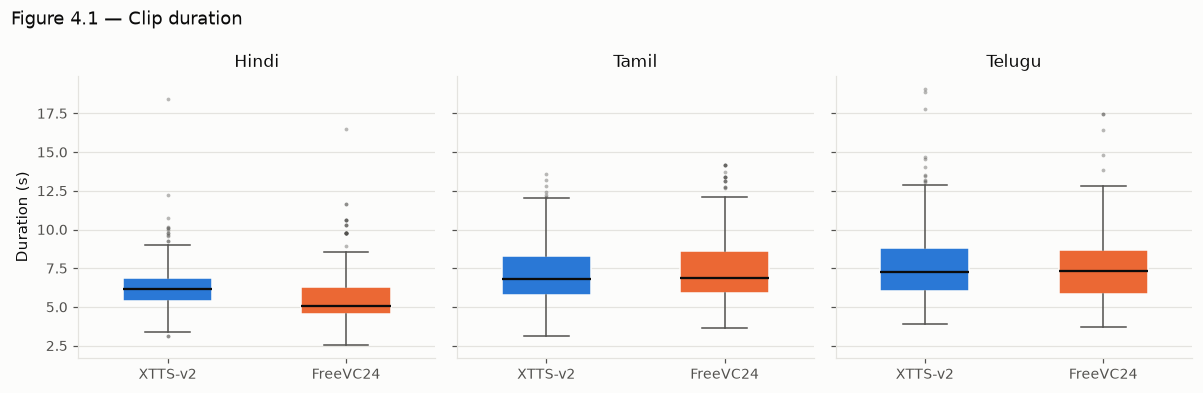

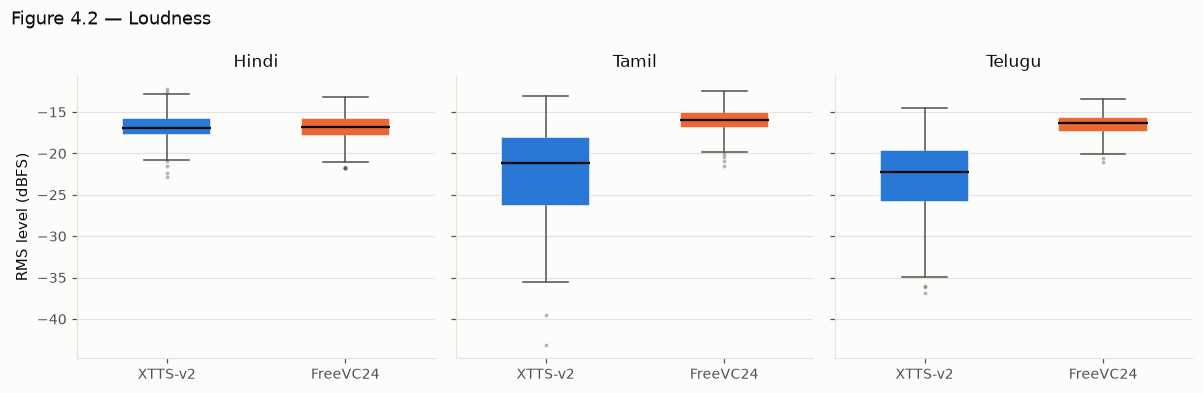

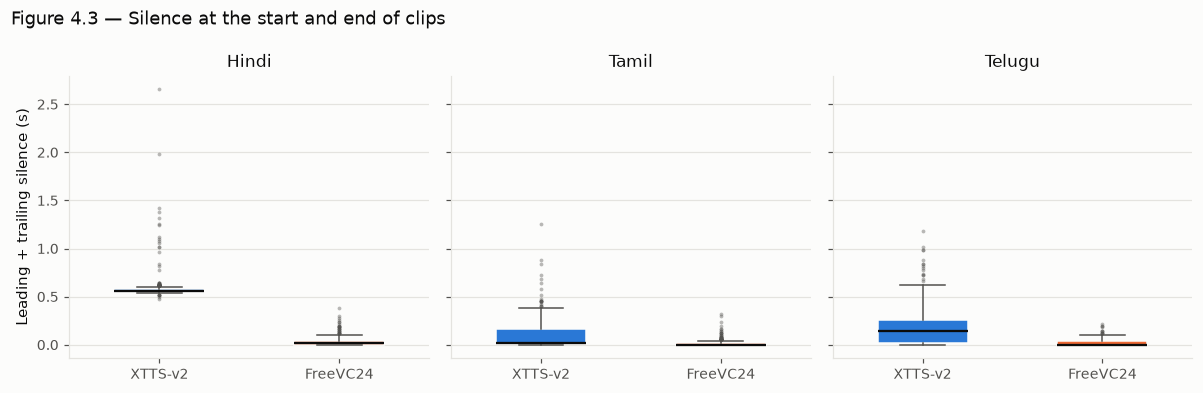

In [14]:
box_by_generator(ok, "duration", "Duration (s)", "Figure 4.1 — Clip duration")
box_by_generator(ok, "rms_dbfs", "RMS level (dBFS)", "Figure 4.2 — Loudness")
ok = ok.assign(edge_silence_s=ok.lead_silence_s + ok.trail_silence_s)
box_by_generator(ok, "edge_silence_s", "Leading + trailing silence (s)", "Figure 4.3 — Silence at the start and end of clips")

**Bandwidth.** Kathbath's real recordings are stored at 16 kHz, so they contain no energy above
8 kHz. If IndicSynth clips keep energy above 8 kHz, a detector could separate real from fake by
bandwidth alone instead of by voice. The average spectrum per generator shows how much energy lies
above that line.

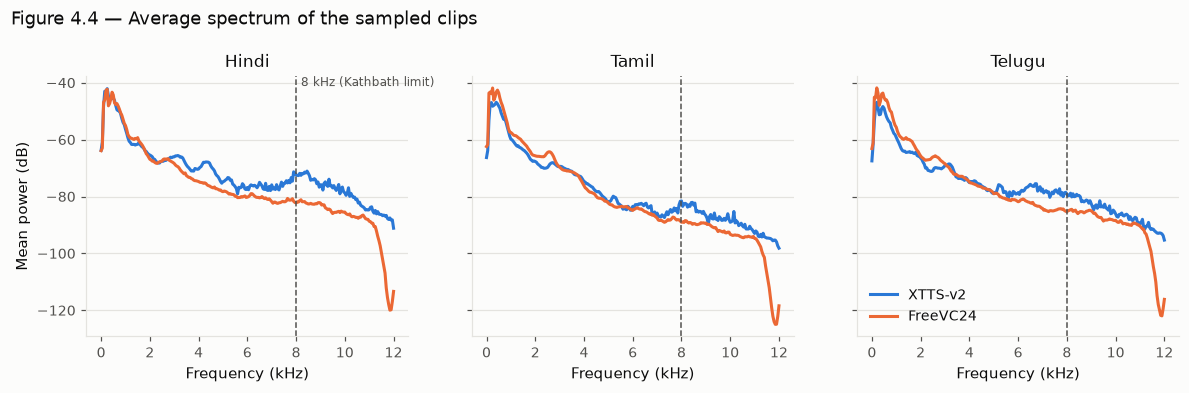

**Table 4.3 — Share of energy above 8 kHz**

,language,generator,energy_above_8kHz_pct
0,Hindi,XTTS-v2,0.370
1,Hindi,FreeVC24,0.050
2,Tamil,XTTS-v2,0.070
3,Tamil,FreeVC24,0.010
4,Telugu,XTTS-v2,0.200
5,Telugu,FreeVC24,0.030


In [15]:
spectra_ok = spectra[sample.error.isna()]
fig, axes = plt.subplots(1, len(LANGUAGES), figsize=(11, 3.6), sharey=True)
above_8k = []
for ax, language in zip(axes, LANGUAGES):
    for generator in GENERATORS:
        mask = ((ok.language == language) & (ok.generator == generator)).to_numpy()
        mean_power = np.nanmean(np.stack(spectra_ok[mask].to_numpy()), axis=0)
        ax.plot(FREQS / 1000, 10 * np.log10(mean_power + 1e-20), color=COLORS[generator], linewidth=2,
                label=GENERATOR_NAMES[generator])
        valid = ~np.isnan(mean_power)
        above_8k.append({"language": language, "generator": GENERATOR_NAMES[generator],
                         "energy_above_8kHz_pct": 100 * mean_power[valid & (FREQS > 8000)].sum() / mean_power[valid].sum()})
    ax.axvline(8, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(language, color=INK)
    ax.set_xlabel("Frequency (kHz)", color=INK)
    style_axes(ax)
axes[0].set_ylabel("Mean power (dB)", color=INK)
axes[0].text(8.2, axes[0].get_ylim()[1], "8 kHz (Kathbath limit)", color=INK_MUTED, fontsize=8, va="top")
axes[-1].legend(frameon=False, labelcolor=INK)
fig.suptitle("Figure 4.4 — Average spectrum of the sampled clips", color=INK, x=0.01, ha="left")
fig.tight_layout()
plt.show()
show_table(pd.DataFrame(above_8k), "Table 4.3 — Share of energy above 8 kHz", precision=2)

**Takeaway.** All 3,000 sampled clips decode without errors and are **24 kHz mono** (Kathbath: 16 kHz).
The storage format differs by generator: XTTS-v2 Tamil and Telugu clips are 32-bit float WAV, all
others 16-bit PCM (Table 4.1b). Durations are similar for both generators (medians 5–7 s, no clip
under 1 s). From the mean durations, the three subsets hold about **1,260 hours** of audio in total
(Table 4.2). Three generator-specific traits could become shortcuts for a detector:

- XTTS-v2 Hindi clips end with about 0.56 s of silence; FreeVC24 clips have almost none (Figure 4.3);
- XTTS-v2 Tamil and Telugu clips are 5–6 dB quieter than FreeVC24 clips (Figure 4.2);
- FreeVC24's spectrum drops sharply above about 11 kHz (Figure 4.4).

Very little energy lies above 8 kHz (at most 0.4%, Table 4.3), so resampling everything to 16 kHz
removes the bandwidth difference to Kathbath. Preprocessing therefore has to resample to 16 kHz,
convert to 16-bit PCM, trim leading and trailing silence and normalise loudness, for real and fake
clips alike.

## 5. Split strategy and leakage

The project splits Kathbath and IndicSynth **by speaker**: 70% of the speakers of each language go to
train, 15% to validation and 15% to test, balanced by gender. A real clip follows its speaker. An
IndicSynth clip is kept only if **every** Kathbath speaker it involves is in the **same** split:
the target speaker for XTTS-v2, and both the source and the target speaker for FreeVC24.

This section simulates that rule with the fixed seed on the IndicSynth speakers, to see how many
clips each split would get and how many FreeVC24 clips would be dropped because their two speakers
fall in different splits. The final split is made later together with the Kathbath real clips.

**Table 5.1 — Simulated speaker-disjoint split (clips)**

split               train  valid   test  dropped
language generator                              
Hindi    freevc24   51308   2044   2044    49340
         xtts_v2    71142  15030  15030        0
Tamil    freevc24   69266   3060   3060    68650
         xtts_v2    96192  21042  21042        0
Telugu   freevc24   41850   1500   1788    40590
         xtts_v2    59118  12024  13026        0

**Table 5.2 — FreeVC24 clips dropped because source and target speakers fall in different splits**

,freevc24_dropped_pct
language,
Hindi,47.100
Tamil,47.700
Telugu,47.300


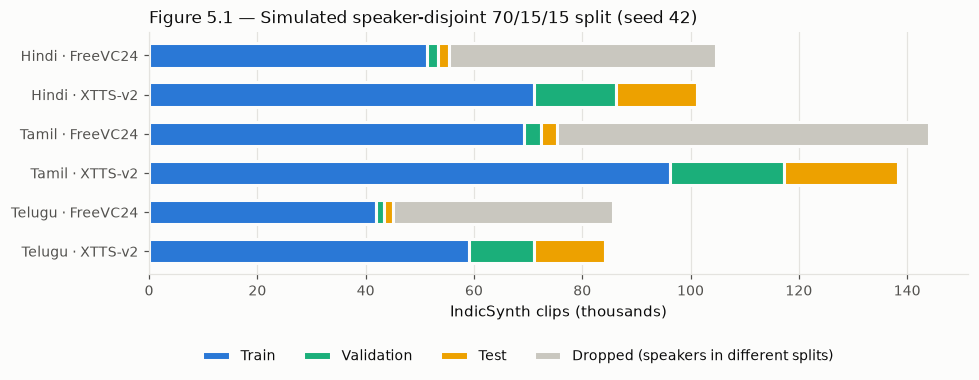

In [16]:
rng = np.random.default_rng(SEED)
speaker_split = {}
for language in LANGUAGES:
    part = meta[meta.language == language]
    genders = part.groupby("target_speaker").gender.first()
    for source in part.source_speaker.dropna().unique():  # source-only speakers take their gender from the file name
        if source not in genders.index:
            genders[source] = "Female" if part[part.source_speaker == source].source_ref_gender.iloc[0] == "f" else "Male"
    for gender in ["Female", "Male"]:
        ids = np.sort(genders[genders == gender].index.to_numpy())
        rng.shuffle(ids)
        n_train, n_valid = round(0.70 * len(ids)), round(0.15 * len(ids))
        for i, speaker in enumerate(ids):
            speaker_split[(language, speaker)] = "train" if i < n_train else ("valid" if i < n_train + n_valid else "test")

meta["target_split"] = [speaker_split[(l, s)] for l, s in zip(meta.language, meta.target_speaker)]
meta["source_split"] = [speaker_split[(l, s)] if pd.notna(s) else None for l, s in zip(meta.language, meta.source_speaker)]
meta["kept"] = meta.source_split.isna() | (meta.source_split == meta.target_split)
meta["split"] = np.where(meta.kept, meta.target_split, "dropped")

show_table(pd.crosstab([meta.language, meta.generator], meta.split)[["train", "valid", "test", "dropped"]],
           "Table 5.1 — Simulated speaker-disjoint split (clips)", precision=0)
fv = meta[meta.generator == "freevc24"]
show_table(fv.groupby("language").kept.agg(lambda k: round(100 * (1 - k.mean()), 1)).rename("freevc24_dropped_pct").to_frame(),
           "Table 5.2 — FreeVC24 clips dropped because source and target speakers fall in different splits", precision=1)

split_counts = pd.crosstab([meta.language, meta.generator], meta.split)[["train", "valid", "test", "dropped"]] / 1000
split_colors = {"train": "#2a78d6", "valid": "#1baf7a", "test": "#eda100", "dropped": "#c9c7bf"}
split_names = {"train": "Train", "valid": "Validation", "test": "Test", "dropped": "Dropped (speakers in different splits)"}
labels = [f"{language} · {GENERATOR_NAMES[generator]}" for language, generator in split_counts.index]
fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(labels))[::-1]
left = np.zeros(len(labels))
for split in split_counts.columns:
    ax.barh(y, split_counts[split], left=left, height=0.62, color=split_colors[split], label=split_names[split],
            edgecolor=SURFACE, linewidth=2)
    left += split_counts[split].to_numpy()
ax.set_yticks(y, labels, color=INK)
ax.set_xlabel("IndicSynth clips (thousands)", color=INK)
style_axes(ax, grid_axis="x")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.45, -0.42), ncol=4, labelcolor=INK)
ax.set_title("Figure 5.1 — Simulated speaker-disjoint 70/15/15 split (seed 42)", color=INK, loc="left")
fig.tight_layout()
plt.show()

In [17]:
leakage = []
for language in LANGUAGES:
    kept = meta[(meta.language == language) & meta.kept]
    speakers_per_split = {s: set(kept[kept.split == s].target_speaker) | set(kept[kept.split == s].source_speaker.dropna())
                          for s in ["train", "valid", "test"]}
    overlap = sum(len(speakers_per_split[a] & speakers_per_split[b])
                  for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")])
    xt = kept[kept.generator == "xtts_v2"]
    sentence_overlap = len(set(xt[xt.split == "train"].transcript) & set(xt[xt.split == "test"].transcript))
    leakage.append({"language": language, "speakers_in_two_splits": overlap,
                    "xtts_sentences_in_train_and_test": sentence_overlap,
                    "xtts_test_sentences": xt[xt.split == "test"].transcript.nunique()})
show_table(pd.DataFrame(leakage), "Table 5.3 — Leakage checks on the simulated split", precision=0)

**Table 5.3 — Leakage checks on the simulated split**

,language,speakers_in_two_splits,xtts_sentences_in_train_and_test,xtts_test_sentences
0,Hindi,0,7772,13641
1,Tamil,0,12603,17981
2,Telugu,0,7002,11719


**Takeaway.** The speaker-disjoint split leaves no speaker in two splits (Table 5.3), but the rule
for FreeVC24 drops about **47%** of its clips, because a random split separates the source and target
speaker about half the time. About 51k (Hindi), 69k (Tamil) and 42k (Telugu) FreeVC24 clips still
remain for training, far more than needed, and 1,500–3,000 per language for validation and test.
Sentence text does overlap between train and test XTTS-v2 clips (57–70% of test sentences), because
Kathbath has several speakers read the same sentences. This is overlap in content, not in speakers;
it is reported here, and test clips can be filtered by sentence if needed.

## 6. Conclusions and requirement checklist

In [18]:
runtime_min = (time.perf_counter() - START_TIME) / 60
checklist = pd.DataFrame([
    ("Identify and verify the data source", "1", "Table 1.1 (rows match the dataset card)"),
    ("Ownership, format and usage constraints", "Intro, 1, 4", "CC BY-NC 4.0; parquet + WAV; Table 4.1"),
    ("Size, feature distribution, characteristics", "2, 4", "Tables 2.1–2.4, 4.2; Figures 2.1, 4.1–4.4"),
    ("Missing values, inconsistencies, duplicates", "1, 4", "Tables 1.1, 4.1, 4.1b"),
    ("Noise / audio quality", "4", "Tables 4.1–4.3; Figures 4.2–4.4"),
    ("Link to the other datasets (Kathbath)", "3", "Tables 3.1–3.6"),
    ("Split strategy and leakage", "5", "Tables 5.1–5.3, Figure 5.1"),
    ("Reproducibility", "0", f"pinned revision {HF_REVISION[:8]}, seed {SEED}, runtime {runtime_min:.1f} min"),
], columns=["requirement", "section", "evidence"])
show_table(checklist, "Table 6.1 — Milestone-2 requirements covered by this notebook", precision=0)

export_columns = ["language", "generator", "audio_path", "file", "row_group", "row_in_group", "target_speaker",
                  "source_speaker", "gender", "target_ref", "source_ref", "transcript", "target_speaker_side",
                  "target_ref_split", "source_ref_split", "target_split", "source_split", "split"]
meta[export_columns].to_parquet(WORK_DIR / "indicsynth_metadata.parquet", index=False)
sample.to_csv(WORK_DIR / "indicsynth_audio_sample.csv", index=False)
print(f"Metadata:     {WORK_DIR / 'indicsynth_metadata.parquet'} ({len(meta):,} rows)")
print(f"Audio sample: {WORK_DIR / 'indicsynth_audio_sample.csv'} ({len(sample):,} rows)")
print(f"Notebook runtime: {runtime_min:.1f} min")

**Table 6.1 — Milestone-2 requirements covered by this notebook**

,requirement,section,evidence
0,Identify and verify the data source,1,Table 1.1 (rows match the dataset card)
1,"Ownership, format and usage constraints","Intro, 1, 4",CC BY-NC 4.0; parquet + WAV; Table 4.1
2,"Size, feature distribution, characteristics","2, 4","Tables 2.1–2.4, 4.2; Figures 2.1, 4.1–4.4"
3,"Missing values, inconsistencies, duplicates","1, 4","Tables 1.1, 4.1, 4.1b"
4,Noise / audio quality,4,Tables 4.1–4.3; Figures 4.2–4.4
5,Link to the other datasets (Kathbath),3,Tables 3.1–3.6
6,Split strategy and leakage,5,"Tables 5.1–5.3, Figure 5.1"
7,Reproducibility,0,"pinned revision c0a10386, seed 42, runtime 7.8..."


Metadata:     /home/himanshu/myproject/dsai-project/temp/indicsynth/working/indicsynth_metadata.parquet (658,146 rows)
Audio sample: /home/himanshu/myproject/dsai-project/temp/indicsynth/working/indicsynth_audio_sample.csv (3,000 rows)
Notebook runtime: 7.8 min


**Final conclusion.** The Hindi, Tamil and Telugu subsets of IndicSynth are clean, complete and
large (658,146 clips, about 1,260 hours), with both generators equally represented and every clip
traceable to a Kathbath speaker and recording. They are adequate as the main training source of
fake Indian-language speech. Four points shape the next steps:

1. IndicSynth uses only Kathbath **train** speakers, so fakes for validation and test come from
   splitting those speakers; Kathbath's own test speakers supply real clips only.
2. FreeVC24 clips are kept only when both speakers share a split, which keeps about half of them.
3. Format, silence and loudness differ by generator, so every clip, real or fake, is resampled to
   16 kHz, stored as 16-bit PCM, trimmed and loudness-normalised in one shared preprocessing step.
4. Tamil speakers are mostly male, so training samples are balanced by gender.